## EDA

In [2]:
# Importing necessary libraries
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier,ExtraTreesClassifier,GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE,SMOTEN,SMOTENC


In [5]:
# loading the Data
df = pd.read_csv(r'C:\Devesh\Credit_Risk_Assessment_ML_Model\data\data.csv')
df.sample(frac=1).head()

,estimate_of_risk,months_since_first_trade,months_since_last_trade,average_duration_of_resolution,number_of_satisfactory_trades,nr_trades_insolvent_for_over_60_days,nr_trades_insolvent_for_over_90_days,percentage_of_legal_trades,months_since_last_illegal_trade,maximum_illegal_trades_over_last_year,...,months_since_last_inquiry_not_recent,nr_inquiries_in_last_6_months,nr_inquiries_in_last_6_months_not_recent,net_fraction_of_revolving_burden,net_fraction_of_installment_burden,nr_revolving_trades_with_balance,nr_installment_trades_with_balance,nr_banks_with_high_ratio,percentage_trades_with_balance,is_at_risk
6958,75,185,2,66,25,0,0,100,-7,7,...,1,2,2,26,67,1,2,-8,75,0
9282,77,510,14,174,25,2,2,100,-7,6,...,14,0,0,4,64,4,1,1,46,0
2599,63,192,2,145,12,2,1,88,5,2,...,-7,0,0,56,88,5,3,1,89,1
2985,82,127,4,57,50,0,0,100,-7,5,...,9,0,0,19,98,6,4,0,59,1
8606,69,447,1,167,21,3,0,80,29,6,...,8,0,0,72,-8,5,1,5,46,1


In [ ]:
# checking the columns
df.columns

Index(['estimate_of_risk', 'months_since_first_trade',
       'months_since_last_trade', 'average_duration_of_resolution',
       'number_of_satisfactory_trades', 'nr_trades_insolvent_for_over_60_days',
       'nr_trades_insolvent_for_over_90_days', 'percentage_of_legal_trades',
       'months_since_last_illegal_trade',
       'maximum_illegal_trades_over_last_year', 'maximum_illegal_trades',
       'nr_total_trades', 'nr_trades_initiated_in_last_year',
       'percentage_of_installment_trades',
       'months_since_last_inquiry_not_recent', 'nr_inquiries_in_last_6_months',
       'nr_inquiries_in_last_6_months_not_recent',
       'net_fraction_of_revolving_burden',
       'net_fraction_of_installment_burden',
       'nr_revolving_trades_with_balance',
       'nr_installment_trades_with_balance', 'nr_banks_with_high_ratio',
       'percentage_trades_with_balance', 'is_at_risk'],
      dtype='str')

In [11]:
# checking info of data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10459 entries, 0 to 10458
Data columns (total 24 columns):
 #   Column                                    Non-Null Count  Dtype
---  ------                                    --------------  -----
 0   estimate_of_risk                          10459 non-null  int64
 1   months_since_first_trade                  10459 non-null  int64
 2   months_since_last_trade                   10459 non-null  int64
 3   average_duration_of_resolution            10459 non-null  int64
 4   number_of_satisfactory_trades             10459 non-null  int64
 5   nr_trades_insolvent_for_over_60_days      10459 non-null  int64
 6   nr_trades_insolvent_for_over_90_days      10459 non-null  int64
 7   percentage_of_legal_trades                10459 non-null  int64
 8   months_since_last_illegal_trade           10459 non-null  int64
 9   maximum_illegal_trades_over_last_year     10459 non-null  int64
 10  maximum_illegal_trades                    10459 non-null  int64
 11  

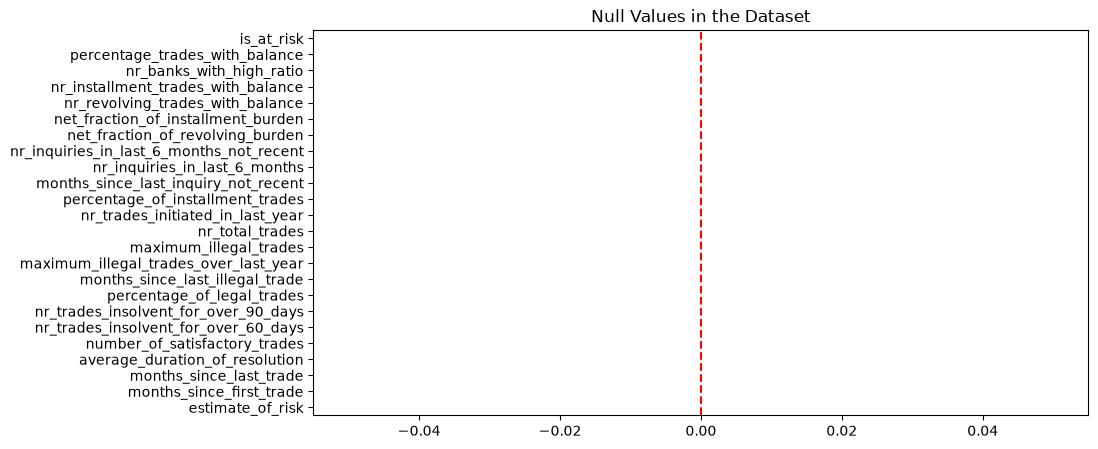

In [38]:
# checking null 
plt.figure(figsize=(10,5))
df.isnull().sum().plot(kind='barh')
plt.title('Null Values in the Dataset')
plt.axvline(0,color='r',linestyle='--')
plt.show()

In [ ]:
# checking  duplicate values
df.duplicated().sum()
# 587 duplicates present

# removing duplicates
df = df.drop_duplicates()

# again checking  duplicate values
df.duplicated().sum()  #0

np.int64(0)

<Axes: >

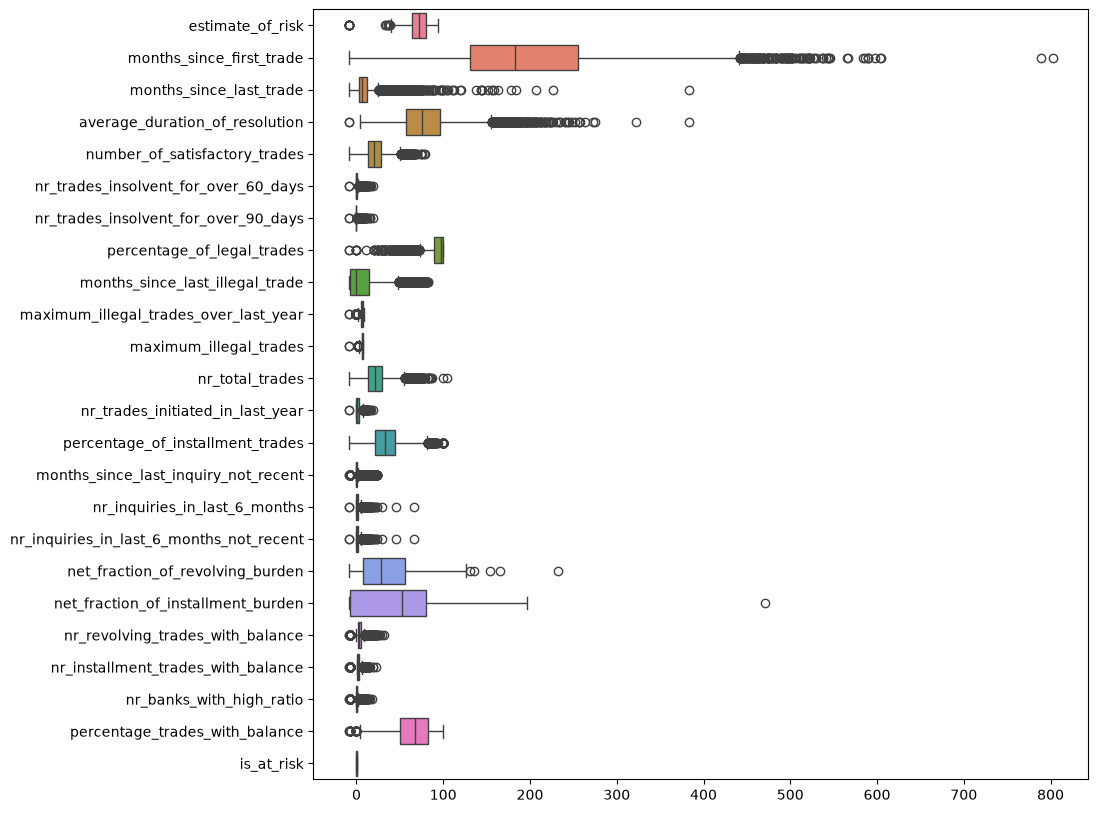

In [56]:
# Checking outlieras using Boxplot
plt.figure(figsize=(10,10))
sns.boxplot(df,orient='h')

In [57]:
# checking Descriptive Stats of data using orderedict
from collections import OrderedDict

stats = []
for i in df.columns:
    order = OrderedDict({
        'Feature':df[i].name,
        'Count':df[i].count(),
        'Min':df[i].min(),
        'Max':df[i].max(),
        'Mean':df[i].mean(),
        'Median':df[i].median(),
        'Q1':df[i].quantile(0.25),
        'Q3':df[i].quantile(0.75),
        'IQR':df[i].quantile(0.75)-df[i].quantile(0.25),
        'Std':df[i].std(),
        'Variance':df[i].var(),
        'Skewness':df[i].skew(),
        'Kurtosis':df[i].kurtosis()
    })
    stats.append(order)
    
report = pd.DataFrame(stats)
report

,Feature,Count,Min,Max,Mean,Median,Q1,Q3,IQR,Std,Variance,Skewness,Kurtosis
0,estimate_of_risk,9872,-9,94,71.962723,72.0,64.0,80.00,16.00,10.262339,105.315599,-0.569406,3.627438
1,months_since_first_trade,9872,-9,803,195.668152,183.0,131.0,255.00,124.00,101.971506,10398.188113,0.555804,0.527979
2,months_since_last_trade,9872,-9,383,9.583874,6.0,3.0,12.00,9.00,12.965164,168.095487,7.086232,111.403475
3,average_duration_of_resolution,9872,-9,383,78.755774,76.0,57.0,96.25,39.25,34.084198,1161.732567,0.917271,2.669900
4,number_of_satisfactory_trades,9872,-9,79,21.115883,20.0,13.0,28.00,15.00,11.328820,128.342157,0.798141,0.856800
5,nr_trades_insolvent_for_over_60_days,9872,-9,19,0.579315,0.0,0.0,1.00,1.00,1.246122,1.552821,4.008921,28.599127
6,nr_trades_insolvent_for_over_90_days,9872,-9,19,0.382901,0.0,0.0,0.00,0.00,1.002107,1.004218,5.149585,51.041258
7,percentage_of_legal_trades,9872,-9,100,92.344003,97.0,89.0,100.00,11.00,11.851561,140.459504,-2.499663,8.664022
8,months_since_last_illegal_trade,9872,-9,83,7.698541,0.0,-7.0,15.00,22.00,20.728410,429.666990,1.590570,1.822501
9,maximum_illegal_trades_over_last_year,9872,-9,9,5.755166,6.0,5.0,7.00,2.00,1.657701,2.747972,-1.872627,4.256718
